In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

np.random.seed(42)

# Generate binary classification dataset
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

y = y.reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class distribution:", np.bincount(y.flatten()))

X shape: (1000, 10)
y shape: (1000, 1)
Class distribution: [498 502]


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Train shape: (800, 10)
Test shape: (200, 10)


In [3]:
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.01, epochs=1000, verbose=True, verbose_every=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.verbose = verbose
        self.verbose_every = verbose_every

        self.weights = None
        self.bias = None
        self.cost_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        m, n = X.shape

        self.weights = np.random.randn(n, 1) * 0.01
        self.bias = np.zeros((1,1))

        if self.verbose:
            print(f"Logistic Regression Training:")
            print(f" X shape: {X.shape}")
            print(f" y shape: {y.shape}")
            print(f" weights shape: {self.weights.shape}")
            print("-" * 50)

        for epoch in range(self.epochs):

            # Forward Pass
            z = X.dot(self.weights) + self.bias # (m, 1)

            # Sigmoid activation - converts to probability
            y_hat = self._sigmoid(z)            # (m, 1)


            # Compute Cost
            y_hat_clipped = np.clip(y_hat, 1e-7, 1 - 1e-7)
            cost = -(1/m) * np.sum(
                y * np.log(y_hat_clipped) + 
                (1 - y) * np.log(1 - y_hat_clipped)
            )
            self.cost_history.append(cost)
            
            # COMPUTE GRADIENTS 
            # Identical to Linear Regression — just errors are different
            errors = y_hat - y                    # (m, 1)
            dW = (1/m) * X.T.dot(errors)          # (n, 1)
            db = (1/m) * np.sum(errors)            # scalar
            
            # UPDATE PARAMETERS 
            self.weights = self.weights - self.learning_rate * dW
            self.bias = self.bias - self.learning_rate * db
            
            if self.verbose and epoch % self.verbose_every == 0:
                print(f"Epoch {epoch:4d}/{self.epochs} | "
                      f"Cost: {cost:.6f}")
        
        if self.verbose:
            print("-" * 50)
            print(f"Training complete!")
            print(f"Final weights: {self.weights.flatten().round(4)}")
        
        return self
    
    def predict_proba(self, X):
        z = X.dot(self.weights) + self.bias
        return self._sigmoid(z)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)
    
    def score(self, X, y):
        predictions = self.predict(X)
        return np.mean(predictions == y)
    
    def plot_cost_history(self):
        plt.figure(figsize=(10, 5))
        plt.plot(range(self.epochs), self.cost_history, 'b-')
        plt.xlabel('Epoch')
        plt.ylabel('Binary Cross Entropy')
        plt.title('Cost History — Logistic Regression')
        plt.grid(True)
        plt.show()

In [4]:
model = LogisticRegressionGD(
    learning_rate=0.1,
    epochs=1000,
    verbose=True,
    verbose_every=100
)

model.fit(X_train_scaled, y_train)

Logistic Regression Training:
 X shape: (800, 10)
 y shape: (800, 1)
 weights shape: (10, 1)
--------------------------------------------------
Epoch    0/1000 | Cost: 0.691607
Epoch  100/1000 | Cost: 0.396433
Epoch  200/1000 | Cost: 0.388057
Epoch  300/1000 | Cost: 0.386691
Epoch  400/1000 | Cost: 0.386387
Epoch  500/1000 | Cost: 0.386311
Epoch  600/1000 | Cost: 0.386291
Epoch  700/1000 | Cost: 0.386286
Epoch  800/1000 | Cost: 0.386284
Epoch  900/1000 | Cost: 0.386284
--------------------------------------------------
Training complete!
Final weights: [ 0.055   0.4517  0.0263  0.1157  0.5759 -1.2811  0.1318  0.0354  0.1592
  1.1093]


In [5]:
# Predictions
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)

# Accuracy
print(f"Our Model Accuracy: {model.score(X_test_scaled, y_test):.4f}")

# Compare with sklearn
sk_model = LogisticRegression(random_state=42)
sk_model.fit(X_train_scaled, y_train.ravel())
print(f"Sklearn Accuracy:   {sk_model.score(X_test_scaled, y_test.ravel()):.4f}")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# ROC-AUC
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

Our Model Accuracy: 0.8200
Sklearn Accuracy:   0.8200

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.77      0.81       100
           1       0.79      0.87      0.83       100

    accuracy                           0.82       200
   macro avg       0.82      0.82      0.82       200
weighted avg       0.82      0.82      0.82       200

ROC-AUC Score: 0.8797


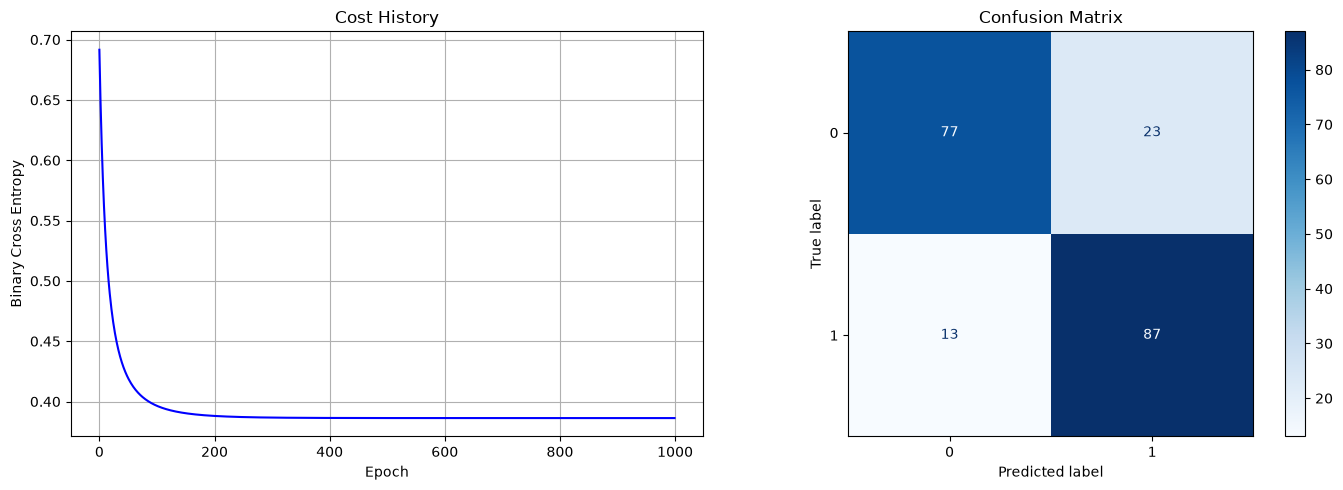

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: cost history
axes[0].plot(range(model.epochs), model.cost_history, 'b-')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross Entropy')
axes[0].set_title('Cost History')
axes[0].grid(True)

# Plot 2: confusion matrix (one-liner)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix')

plt.tight_layout()
plt.show()

In [7]:
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

print(f"{'Threshold':<12} {'Precision':>10} {'Recall':>10} {'FP':>6} {'FN':>6}")
print("-" * 48)

for t in thresholds:
    preds = model.predict(X_test_scaled, threshold=t)
    
    tp = np.sum((preds == 1) & (y_test == 1))
    fp = np.sum((preds == 1) & (y_test == 0))
    fn = np.sum((preds == 0) & (y_test == 1))
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn)
    
    print(f"{t:<12} {precision:>10.3f} {recall:>10.3f} {fp:>6} {fn:>6}")

Threshold     Precision     Recall     FP     FN
------------------------------------------------
0.1               0.636      0.980     56      2
0.3               0.722      0.910     35      9
0.5               0.791      0.870     23     13
0.7               0.812      0.690     16     31
0.9               0.889      0.400      5     60


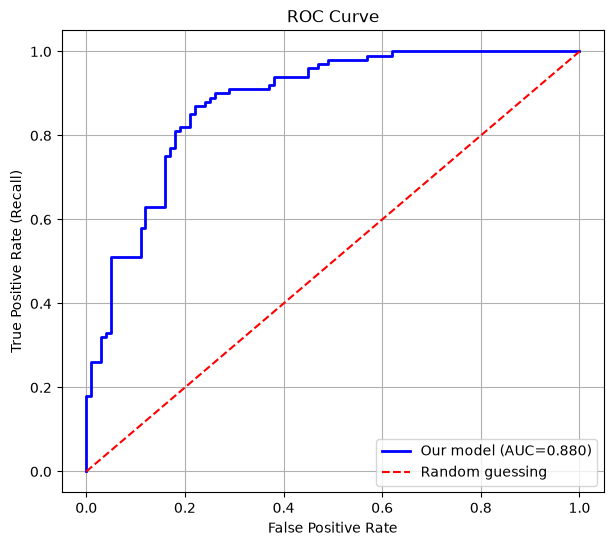

Best threshold (Youden): 0.504
TPR: 0.870, FPR: 0.220


In [8]:
from sklearn.metrics import roc_curve

fpr, tpr, thresh = roc_curve(y_test, y_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, 'b-', linewidth=2, label=f'Our model (AUC={roc_auc_score(y_test, y_proba):.3f})')
plt.plot([0, 1], [0, 1], 'r--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
print(f"Best threshold (Youden): {thresh[best_idx]:.3f}")
print(f"TPR: {tpr[best_idx]:.3f}, FPR: {fpr[best_idx]:.3f}")

## Logistic Regression Summary

Predicts the probability of class 1 using the sigmoid function.

### Model
z = Xθ + b
ŷ = σ(z) = 1 / (1 + e⁻ᶻ)

### Cost Function: Binary Cross Entropy
J = -(1/m) Σ [y·log(ŷ) + (1-y)·log(1-ŷ)]
- Convex, so gradient descent finds the global minimum
- MSE with sigmoid is non-convex, so it is not used

### Gradient
dW = (1/m) Xᵀ(ŷ - y)  (same form as Linear Regression)
db = (1/m) Σ(ŷ - y)

### Decision Threshold
- Default 0.5: ŷ ≥ 0.5 → class 1
- Lower threshold → higher recall, lower precision (more FP, fewer FN)
- Higher threshold → higher precision, lower recall (fewer FP, more FN)
- Best threshold depends on the cost of each error

### Evaluation
- Confusion matrix: TP, TN, FP, FN
- Precision = TP/(TP+FP), Recall = TP/(TP+FN)
- ROC curve: TPR vs FPR across all thresholds
- AUC: 0.5 = random, 1.0 = perfect
- Youden's J = TPR - FPR picks the best balanced threshold

### Choosing a Threshold
1. Cost-based: minimize cost_fp×FP + cost_fn×FN
2. Youden's J (no cost info)
3. Maximize F1
4. Business constraint (e.g. recall ≥ 0.95)
Always tune on validation data, not the test set.

In [6]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X2, y2 = make_classification(
    n_samples=300,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.0,
    random_state=42
)

y2 = y2.reshape(-1,1)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

scaler2 = StandardScaler()
X2_train_s = scaler2.fit_transform(X2_train)
X2_test_s = scaler2.transform(X2_test)

model2 = LogisticRegressionGD(learning_rate=0.1, epochs=1000, verbose=False)
model2.fit(X2_train_s, y2_train)

print("weights:", model2.weights.flatten())
print("Bias:", model2.bias.flatten())
print("Test accuracy:", model2.score(X2_test_s, y2_test))

weights: [0.49841146 4.04541417]
Bias: [0.11197317]
Test accuracy: 0.95


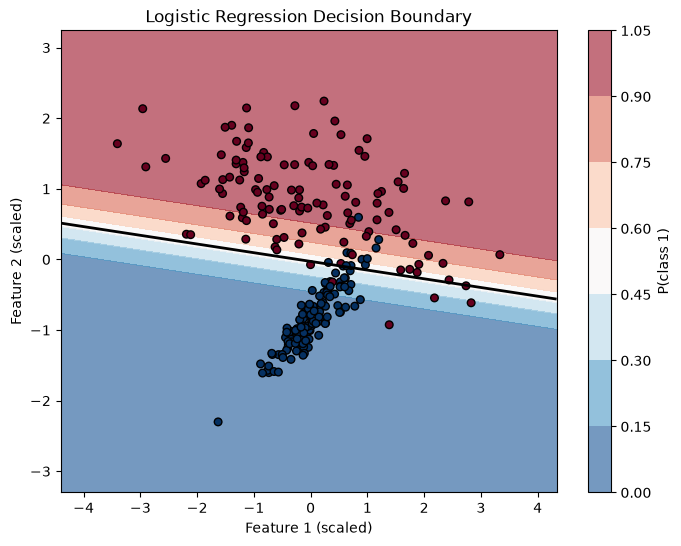

In [14]:
# Grid covering the feature space
x1_min, x1_max = X2_train_s[:, 0].min() - 1, X2_train_s[:, 0].max() + 1
x2_min, x2_max = X2_train_s[:, 1].min() - 1, X2_train_s[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 300),
    np.linspace(x2_min, x2_max, 300)
)

# Predicted probability at every grid point
grid = np.c_[xx1.ravel(), xx2.ravel()]          # shape (90000, 2)
probs = model2.predict_proba(grid).reshape(xx1.shape)

plt.figure(figsize=(8, 6))

# Colored probability regions
plt.contourf(xx1, xx2, probs, cmap='RdBu_r', alpha=0.6)
plt.colorbar(label='P(class 1)')

# The decision boundary: where probability = 0.5
plt.contour(xx1, xx2, probs, levels=[0.5], colors='black', linewidths=2)

# Training points
plt.scatter(X2_train_s[:, 0], X2_train_s[:, 1],
            c=y2_train.flatten(), cmap='RdBu_r', edgecolors='k', s=30)

plt.xlabel('Feature 1 (scaled)')
plt.ylabel('Feature 2 (scaled)')
plt.title('Logistic Regression Decision Boundary')
plt.show()

## Regularization in Logistic Regression

Large weights make the model overconfident: the sigmoid saturates and probabilities
pile up near 0 and 1. If the classes are perfectly separable, the weights grow
without limit. An L2 penalty on the weights prevents this.

### Cost and gradient
J = BCE + (alpha / 2m) * sum(w^2)
dW = (1/m) X^T (y_hat - y) + (alpha/m) * w
db = (1/m) sum(y_hat - y)   (bias is not penalized)

### alpha vs C
- sklearn uses C = 1 / alpha
- Small C = strong regularization, large C = weak regularization
- sklearn's default is C=1.0, so it regularizes mildly by default

### What we observed (2-feature dataset)
- Weights shrink as alpha increases
- The useless feature (w1) shrank much faster than the useful one (w2)
- Accuracy barely changes, and small test sets (60 points) make accuracy differences unreliable
- Log loss rises with alpha, and mean confidence falls toward 0.5
- A model can have perfect accuracy but be barely confident, so check log loss, not just accuracy

### Key points
- Regularization helps when the model overfits (many features, few samples)
- It costs probability sharpness when the model was not overfitting
- Choose alpha (or C) with cross validation on training data, never on the test set
- Scale features before regularizing, as with Ridge

In [5]:
class LogisticRegressionGDWithPenalty:
    def __init__(self, learning_rate=0.01, epochs=1000, alpha=0.0, verbose=True, verbose_every=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.alpha = alpha            # NEW: regularization strength (0 = no regularization)
        self.verbose = verbose
        self.verbose_every = verbose_every

        self.weights = None
        self.bias = None
        self.cost_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        m, n = X.shape

        self.weights = np.random.randn(n, 1) * 0.01
        self.bias = np.zeros((1, 1))
        self.cost_history = []        # NEW: reset so refitting doesn't append to old history

        if self.verbose:
            print("Logistic Regression Training:")
            print(f"  Alpha: {self.alpha}")
            print(f"  X shape: {X.shape}")
            print(f"  y shape: {y.shape}")
            print(f"  weights shape: {self.weights.shape}")
            print("-" * 50)

        for epoch in range(self.epochs):

            # Forward pass
            z = X.dot(self.weights) + self.bias          # (m, 1)
            y_hat = self._sigmoid(z)                     # (m, 1)

            # Cost: binary cross entropy + L2 penalty
            y_hat_clipped = np.clip(y_hat, 1e-7, 1 - 1e-7)
            bce = -(1/m) * np.sum(
                y * np.log(y_hat_clipped) + (1 - y) * np.log(1 - y_hat_clipped)
            )
            l2_penalty = (self.alpha / (2*m)) * np.sum(self.weights ** 2)   # NEW
            cost = bce + l2_penalty                                          # NEW
            self.cost_history.append(cost)

            # Gradients
            errors = y_hat - y                                               # (m, 1)
            dW = (1/m) * X.T.dot(errors) + (self.alpha/m) * self.weights     # NEW: penalty term
            db = (1/m) * np.sum(errors)                                      # bias is NOT penalized

            # Update
            self.weights = self.weights - self.learning_rate * dW
            self.bias = self.bias - self.learning_rate * db

            if self.verbose and epoch % self.verbose_every == 0:
                print(f"Epoch {epoch:4d}/{self.epochs} | "
                      f"Cost: {cost:.6f} | BCE: {bce:.6f} | Penalty: {l2_penalty:.6f}")

        if self.verbose:
            print("-" * 50)
            print("Training complete!")
            print(f"Final weights: {self.weights.flatten().round(4)}")
            print(f"Final bias: {self.bias.flatten()[0]:.4f}")

        return self

    def predict_proba(self, X):
        z = X.dot(self.weights) + self.bias
        return self._sigmoid(z)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

    def plot_cost_history(self):
        plt.figure(figsize=(10, 5))
        plt.plot(range(self.epochs), self.cost_history, 'b-')
        plt.xlabel('Epoch')
        plt.ylabel('Cost (BCE + L2 penalty)')
        plt.title('Cost History: Logistic Regression')
        plt.grid(True)
        plt.show()

In [6]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X3, y3 = make_classification(
    n_samples = 600, n_features=2, n_informative=2, n_redundant=0,
    n_classes=3, n_clusters_per_class=1, class_sep=1.2, random_state=42
)

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3
)

scaler3 = StandardScaler()
X3_train_s = scaler3.fit_transform(X3_train)
X3_test_s = scaler3.transform(X3_test)

print("Classes:", np.unique(y3))
print("Class counts (train):", np.bincount(y3_train))
print("y3_train shape:", y3_train.shape)

Classes: [0 1 2]
Class counts (train): [162 158 160]
y3_train shape: (480,)


In [7]:
def softmax(z):
    Z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(Z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def one_hot(y, n_classes):
    out = np.zeros((len(y), n_classes))
    out[np.arange(len(y)), y] = 1
    return out

# quick check with the example from before
z_test = np.array([[2.0, 1.0, 0.1]])
print("softmax:", softmax(z_test).round(3))
print("row sum:", softmax(z_test).sum(axis=1))
print("one_hot([0, 2, 1]):\n", one_hot(np.array([0, 2, 1]), 3))

softmax: [[0.659 0.242 0.099]]
row sum: [1.]
one_hot([0, 2, 1]):
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]


In [8]:
class SoftmaxRegressionGD:
    def __init__(self, learning_rate=0.1, epochs=1000, alpha=0.0, verbose=True, verbose_every=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.alpha = alpha              # L2 strength, 0 = none (same as before)
        self.verbose = verbose
        self.verbose_every = verbose_every

        self.weights = None             # shape (n, K)
        self.bias = None                # shape (1, K)
        self.cost_history = []

    def fit(self, X, y):
        m, n = X.shape
        K = len(np.unique(y))           # number of classes
        Y = one_hot(y, K)               # (m, K): labels as 0/1 rows
        self.cost_history = []

        self.weights = np.random.randn(n, K) * 0.01
        self.bias = np.zeros((1, K))

        if self.verbose:
            print(f"m={m}, n={n}, K={K}")
            print(f"X: {X.shape}, Y one-hot: {Y.shape}")
            print(f"weights: {self.weights.shape}, bias: {self.bias.shape}")
            print("-" * 50)

        for epoch in range(self.epochs):

            # Forward pass
            z = X.dot(self.weights) + self.bias        # (m, n)·(n, K) + (1, K) = (m, K)
            y_hat = softmax(z)                         # (m, K), each row sums to 1

            # Categorical cross entropy (+ optional L2)
            y_hat_clipped = np.clip(y_hat, 1e-7, 1 - 1e-7)
            cost = -(1/m) * np.sum(Y * np.log(y_hat_clipped))
            cost += (self.alpha / (2*m)) * np.sum(self.weights ** 2)
            self.cost_history.append(cost)

            # Gradients: same form as binary, now with matrices
            errors = y_hat - Y                                              # (m, K)
            dW = (1/m) * X.T.dot(errors) + (self.alpha/m) * self.weights    # (n, K)
            db = (1/m) * np.sum(errors, axis=0, keepdims=True)              # (1, K)

            # Update
            self.weights = self.weights - self.learning_rate * dW
            self.bias = self.bias - self.learning_rate * db

            if self.verbose and epoch % self.verbose_every == 0:
                print(f"Epoch {epoch:4d}/{self.epochs} | Cost: {cost:.6f}")

        if self.verbose:
            print("-" * 50)
            print("Training complete!")
        return self

    def predict_proba(self, X):
        return softmax(X.dot(self.weights) + self.bias)       # (m, K)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)       # (m,) class with highest probability

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

In [13]:
sm = SoftmaxRegressionGD(learning_rate=0.5, epochs=20000, verbose=True, verbose_every=4000)
sm.fit(X3_train_s, y3_train)

print("\nFinal cost:", round(sm.cost_history[-1], 4))
print("Test accuracy:", sm.score(X3_test_s, y3_test))

m=480, n=2, K=3
X: (480, 2), Y one-hot: (480, 3)
weights: (2, 3), bias: (1, 3)
--------------------------------------------------
Epoch    0/20000 | Cost: 1.098470
Epoch 4000/20000 | Cost: 0.105317
Epoch 8000/20000 | Cost: 0.100774
Epoch 12000/20000 | Cost: 0.099489
Epoch 16000/20000 | Cost: 0.098992
--------------------------------------------------
Training complete!

Final cost: 0.0988
Test accuracy: 0.9833333333333333


In [15]:
sk3 = LogisticRegression(C=1e6, max_iter=1000)
sk3.fit(X3_train_s, y3_train)

ours = sm.predict_proba(X3_test_s)
theirs = sk3.predict_proba(X3_test_s)

print("Sklearn test accuracy:", sk3.score(X3_test_s, y3_test))
print("Max abs probability difference:", np.abs(ours - theirs).max().round(4))

Sklearn test accuracy: 0.9833333333333333
Max abs probability difference: 0.0215


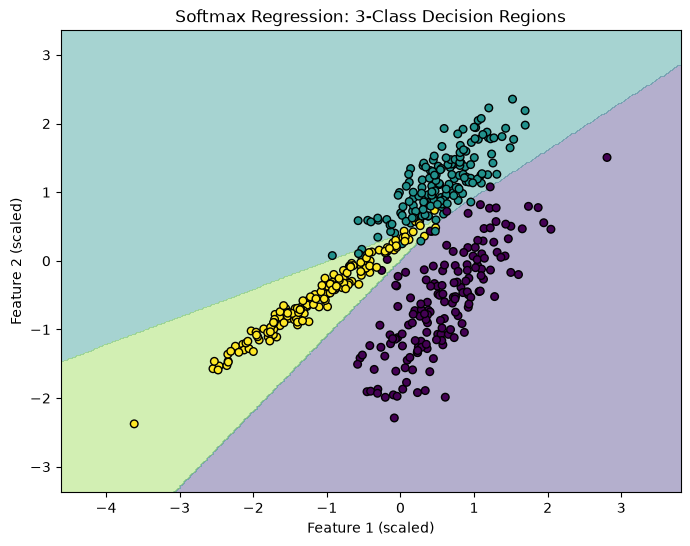

In [18]:
x1_min, x1_max = X3_train_s[:, 0].min() - 1, X3_train_s[:, 0].max() + 1
x2_min, x2_max = X3_train_s[:, 1].min() - 1, X3_train_s[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 300),
    np.linspace(x2_min, x2_max, 300)
)

grid = np.c_[xx1.ravel(), xx2.ravel()]
pred_class = sm.predict(grid).reshape(xx1.shape)     # 0, 1 or 2 at every grid point

plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, pred_class, levels=[-0.5, 0.5, 1.5, 2.5], cmap='viridis', alpha=0.4)
plt.scatter(X3_train_s[:, 0], X3_train_s[:, 1], c=y3_train,
            cmap='viridis', edgecolors='k', s=30)
plt.xlabel('Feature 1 (scaled)')
plt.ylabel('Feature 2 (scaled)')
plt.title('Softmax Regression: 3-Class Decision Regions')
plt.show()